# Environment Corner Plot

Corner plot of driver variables (`log_Mstar`, `log_sSFR`, `log_5NN`, `log_MassA_1`) colour-coded by one SF morphology metric (G/C/A/S) at a time, with the SFMS ridge line overlaid on any Mstar-vs-SFR/sSFR panel. Ported from the old repo's `master/notebooks/environment.ipynb` scaffold onto this pipeline's `master_<date>.csv` schema.

**Data:** reads the most recent `outputs/csv/master_<date>.csv`.

**SFMS:** refit live on whatever subset is currently configured below, using `src/utils/sfms.py` (the same Lee et al. 2015 ridge-line fit `05_sfms.py` uses) - not read from a pre-computed `master_sfms_<date>.csv`, so the ridge line always matches the exact sample being plotted (spectral-class / sample-subset filters included).

**Layout:** functions are defined once, below - only re-run those cells if you change a function itself. To produce a new plot, edit the **Configuration** cell and re-run it plus the **Run** cell after it.

In [ ]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

warnings.filterwarnings("ignore")

# Jupyter's default cwd is the notebook's own directory (sami_sf_pipeline/notebooks/).
PIPELINE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PIPELINE_ROOT / "outputs" / "csv").exists(), (
    f"Couldn't find outputs/csv under {PIPELINE_ROOT} - "
    "run this notebook from sami_sf_pipeline/notebooks/, or adjust PIPELINE_ROOT above."
)
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.sfms import lee2015_sfms, fit_ridge_line

CSV_DIR = PIPELINE_ROOT / "outputs" / "csv"

plt.rcParams.update({
    "figure.dpi":       120,
    "font.family":      "serif",
    "axes.labelsize":   11,
    "axes.titlesize":   11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "axes.grid":        True,
    "grid.alpha":       0.25,
    "grid.linestyle":   "--",
})

Purity-passed sample: N = 837


## Functions

Everything below takes its settings as explicit arguments rather than reading module-level config constants - so these cells only need to be re-run if you change a function's logic, not every time you tweak a setting in the Configuration cell.

In [2]:
MASTER_PATTERN = re.compile(r"^master_(\d{4}-\d{2}-\d{2})\.csv$")


def latest_master_csv() -> Path:
    candidates = sorted(
        (m.group(1), p) for p in CSV_DIR.glob("master_*.csv")
        if (m := MASTER_PATTERN.match(p.name))
    )
    if not candidates:
        raise FileNotFoundError(
            f"No master_<date>.csv found in {CSV_DIR} - run 02_continuum_mask.py, "
            "03_metrics/*.py, then 04_build_master_csv.py first."
        )
    return candidates[-1][1]


def load_and_clean(path: Path) -> pd.DataFrame:
    """Sentinel cleaning + derived columns needed for the corner plot.
    C==-999 and non-finite A do occur (1 each in the current master_<date>.csv) -
    same guard the old master/notebooks/environment.ipynb scaffold had."""
    df = pd.read_csv(path)

    n_bad_c = int((df["C"] == -999).sum())
    n_bad_a = int((~np.isfinite(df["A"]) & df["A"].notna()).sum())
    df.loc[df["C"] == -999, "C"] = np.nan
    df.loc[~np.isfinite(df["A"]) & df["A"].notna(), "A"] = np.nan
    if n_bad_c or n_bad_a:
        print(f"  Sentinel cleaning: C==-999 -> NaN ({n_bad_c}), non-finite A -> NaN ({n_bad_a})")

    # Raw 5NN is a surface density in Mpc^-2, not log-scaled.
    df["log_5NN"] = np.log10(df["5NN"].clip(lower=1e-6))

    # Three-way environment label. group_status (central/satellite/isolated/NaN)
    # is GAMA-only (see README.md "Environment metrics") - Cluster galaxies and
    # any GAMA galaxy Wang has no BCGCATAID for both fall through to "Unknown",
    # not a guessed default.
    conditions = [
        df["environment"] == "Cluster",
        df["group_status"].isin(["central", "satellite"]),
        df["group_status"] == "isolated",
    ]
    choices = ["Cluster", "Group/Field", "Isolated"]
    df["env3"] = np.select(conditions, choices, default="Unknown")

    return df


def prepare_data(df: pd.DataFrame, *, spectral_classes=None, sample_subset="full_sam", ssfr_cut=None) -> pd.DataFrame:
    """
    spectral_classes : None | "pure_SF" | "composite_SF" | list of these
    sample_subset    : "full_sam" -> in_full_sam only (Wang 2022 quality cuts)
                        "all"      -> every galaxy in master_<date>.csv (each plotted
                                      metric/driver still drops its own NaNs per panel)
    ssfr_cut         : hard lower cut on log_sSFR, None to keep all
    """
    out = df.copy()
    print(f"  Raw catalogue   : {len(out):,} galaxies")

    if sample_subset == "full_sam":
        out = out[out["in_full_sam"]]
        print(f"  in_full_sam     : -> {len(out):,}")
    elif sample_subset != "all":
        raise ValueError(f"sample_subset must be 'full_sam' or 'all', got {sample_subset!r}")

    if spectral_classes is not None:
        targets = [spectral_classes] if isinstance(spectral_classes, str) else list(spectral_classes)
        out = out[out["spectral_class"].isin(targets)]
        print(f"  spectral_class {targets}: -> {len(out):,}")

    if ssfr_cut is not None:
        out = out[out["log_sSFR"].isna() | (out["log_sSFR"] >= ssfr_cut)]
        print(f"  log_sSFR >= {ssfr_cut}: -> {len(out):,}")

    print(f"  Final sample    : {len(out):,} galaxies\n")
    return out

In [3]:
def compute_sfms(df: pd.DataFrame, mass_range=(9.0, 11.0), sfr_floor=-1.0) -> dict:
    sf = df[df["log_SFR"].notna() & df["log_Mstar"].notna()].copy()
    sfms_params, ridge_mass, ridge_sfr = fit_ridge_line(
        sf["log_Mstar"].values, sf["log_SFR"].values,
        mass_range=mass_range, sfr_floor=sfr_floor,
    )
    S0, a1, Mt = sfms_params
    print(f"  Lee+2015 fit: S0={S0:.3f}, a1={a1:.3f}, Mt={Mt:.3f}")

    sf_fit = sf[sf["log_SFR"] >= sfr_floor]
    residuals = sf_fit["log_SFR"].values - lee2015_sfms(sf_fit["log_Mstar"].values, S0, a1, Mt)
    sigma = residuals.std()
    print(f"  1-sigma scatter = {sigma:.3f} dex\n")

    return {"params": sfms_params, "sigma": sigma,
            "label": f"SFMS (Lee+2015 ridge fit, N={len(ridge_mass)})"}


def draw_sfms(ax, sfms: dict, x_col: str, y_col: str, mass_range: tuple,
              show=True, scatter_sigma=1.0) -> None:
    """Only draws when x_col=log_Mstar and y_col is SFR-related - handles both
    log_SFR and log_sSFR y-axes, silently no-ops on every other panel."""
    if not show or x_col != "log_Mstar" or y_col not in ("log_SFR", "log_sSFR"):
        return
    S0, a1, Mt = sfms["params"]
    xline = np.linspace(mass_range[0], mass_range[1], 200)
    yline_sfr = lee2015_sfms(xline, S0, a1, Mt)
    yline = yline_sfr - xline if y_col == "log_sSFR" else yline_sfr

    ax.plot(xline, yline, color="black", lw=1.5, label=sfms["label"], zorder=6)
    if scatter_sigma > 0:
        sigma = sfms["sigma"]
        ax.fill_between(xline, yline - scatter_sigma * sigma, yline + scatter_sigma * sigma,
                         color="black", alpha=0.10, zorder=5,
                         label=f"\u00b1{scatter_sigma:.0f}\u03c3 = \u00b1{sigma:.2f} dex")


METRIC_LABELS = {"G": "Gini (G)", "C": "Concentration (C)", "A": "Asymmetry (A)", "S": "Smoothness (S)"}


def plot_corner(df: pd.DataFrame, sfms: dict, *, metric: str, drivers: list,
                 cmap: str = "plasma", sfms_show=True, sfms_scatter=1.0) -> plt.Figure:
    metric_label = METRIC_LABELS.get(metric, metric)
    plot_df = df.dropna(subset=[metric])
    vmin, vmax = plot_df[metric].quantile(0.02), plot_df[metric].quantile(0.98)
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)

    n = len(drivers)
    n_panels = n - 1
    fig, axes = plt.subplots(n_panels, n_panels, figsize=(4.5 * n_panels, 4.5 * n_panels),
                              sharex="col", sharey="row", squeeze=False)
    fig.subplots_adjust(hspace=0.08, wspace=0.08)

    mass_range = (df["log_Mstar"].quantile(0.01), df["log_Mstar"].quantile(0.99))

    for row in range(n_panels):
        for col in range(n_panels):
            ax = axes[row, col]
            x_col = drivers[col]["col"]
            y_col = drivers[row + 1]["col"]

            if col > row:
                ax.set_visible(False)
                continue

            sub = plot_df[[x_col, y_col, metric]].dropna()
            ax.scatter(sub[x_col], sub[y_col], c=sub[metric], cmap=cmap_obj, norm=norm,
                       s=10, alpha=0.55, linewidths=0, rasterized=True)

            draw_sfms(ax, sfms, x_col, y_col, mass_range, show=sfms_show, scatter_sigma=sfms_scatter)

            if x_col == "log_Mstar" and y_col in ("log_SFR", "log_sSFR"):
                ax.legend(fontsize=7, loc="upper left")

            if row == n_panels - 1:
                ax.set_xlabel(drivers[col]["label"], fontsize=11)
            else:
                ax.tick_params(labelbottom=False)
            if col == 0:
                ax.set_ylabel(drivers[row + 1]["label"], fontsize=11)
            else:
                ax.tick_params(labelleft=False)

    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap_obj), cax=cbar_ax, label=metric_label)
    fig.suptitle(f"Corner plot \u2014 colour: {metric_label}  |  N = {len(plot_df):,}", y=1.01, fontsize=12)
    return fig

## Load data

Run once (or re-run after regenerating `master_<date>.csv` via `04_build_master_csv.py`).

In [4]:
master_path = latest_master_csv()
print(f"Using {master_path.name}")
df_raw = load_and_clean(master_path)
print(f"Loaded {len(df_raw):,} galaxies, {df_raw.shape[1]} columns")

Using master_2026-08-17.csv
  Sentinel cleaning: C==-999 -> NaN (1), non-finite A -> NaN (1)
Loaded 3,031 galaxies, 52 columns


## Configuration

Edit this cell, then re-run it and the **Run** cell below.

In [5]:
CORNER_METRIC = "G"          # "G" | "C" | "A" | "S"
SPECTRAL_CLASSES = None      # None | "pure_SF" | "composite_SF" | ["pure_SF", "composite_SF"]
SAMPLE_SUBSET = "full_sam"   # "full_sam" (Wang 2022 quality cuts) | "all" (every galaxy in master_<date>.csv)
SSFR_CUT = None               # e.g. -12.0 to drop passive galaxies; None to keep all

CORNER_DRIVERS = [
    {"col": "log_Mstar",   "label": r"$\log\,M_\star$"},
    {"col": "log_sSFR",    "label": r"$\log\,\mathrm{sSFR}$"},
    {"col": "log_5NN",     "label": r"$\log\,\Sigma_\mathrm{5NN}$"},
    {"col": "log_MassA_1", "label": r"$\log\,M_\mathrm{halo}$"},
]
CORNER_CMAP = "plasma"

SFMS_SHOW = True
SFMS_SCATTER = 1.0            # +/- N-sigma band, 0 to suppress
SFMS_MASS_RANGE = (9.0, 11.0)
SFMS_SFR_FLOOR = -1.0

## Run

Re-run this cell after changing the configuration above.

  Raw catalogue   : 3,031 galaxies
  in_full_sam     : -> 837
  Final sample    : 837 galaxies

  Lee+2015 fit: S0=2.928, a1=0.207, Mt=10.120
  1-sigma scatter = 0.363 dex



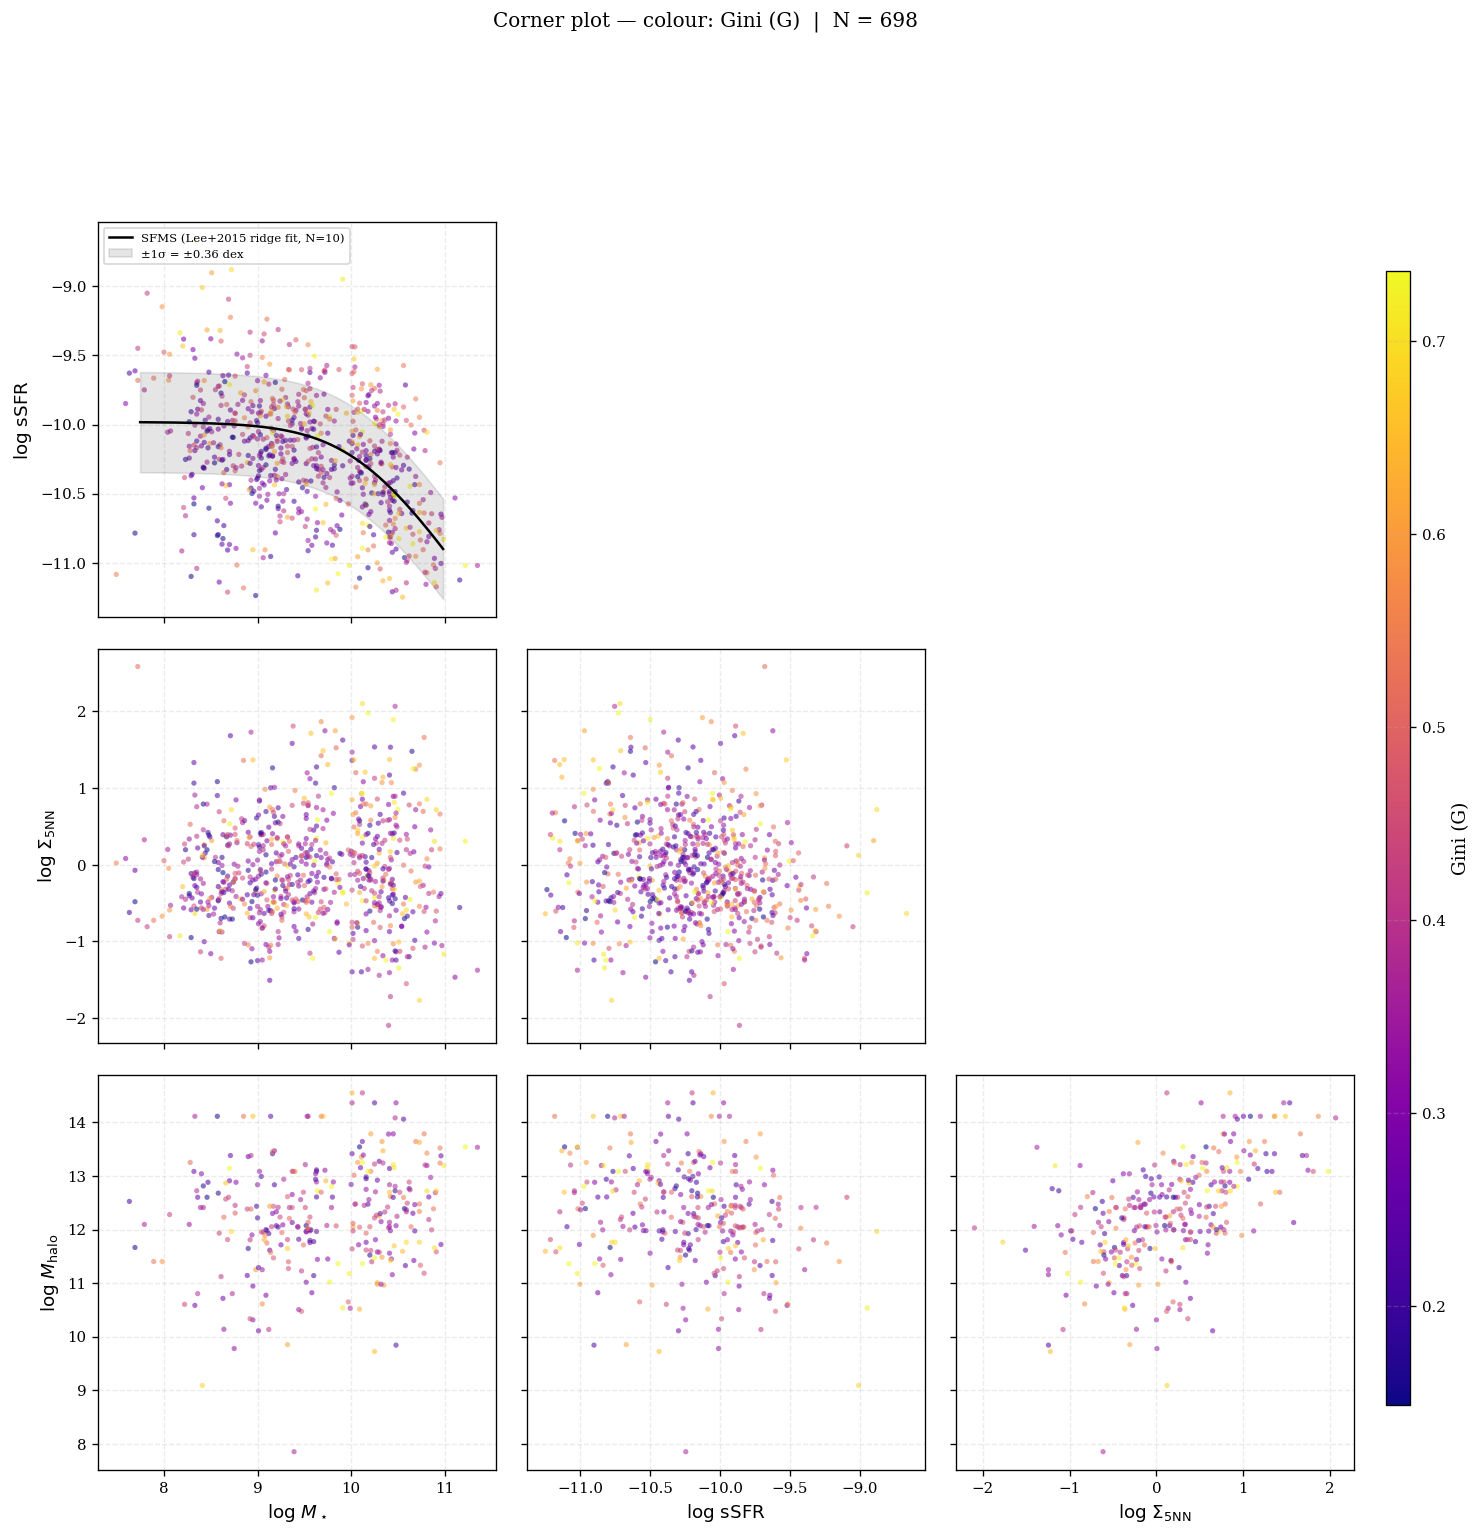

In [6]:
df = prepare_data(df_raw, spectral_classes=SPECTRAL_CLASSES, sample_subset=SAMPLE_SUBSET, ssfr_cut=SSFR_CUT)

sfms = compute_sfms(df, mass_range=SFMS_MASS_RANGE, sfr_floor=SFMS_SFR_FLOOR)

fig = plot_corner(df, sfms, metric=CORNER_METRIC, drivers=CORNER_DRIVERS, cmap=CORNER_CMAP,
                   sfms_show=SFMS_SHOW, sfms_scatter=SFMS_SCATTER)
plt.show()

## All four metrics at once

Convenience cell - produces one corner plot per metric (G, C, A, S) using the sample already prepared above, without editing `CORNER_METRIC` and re-running the Run cell four times by hand.

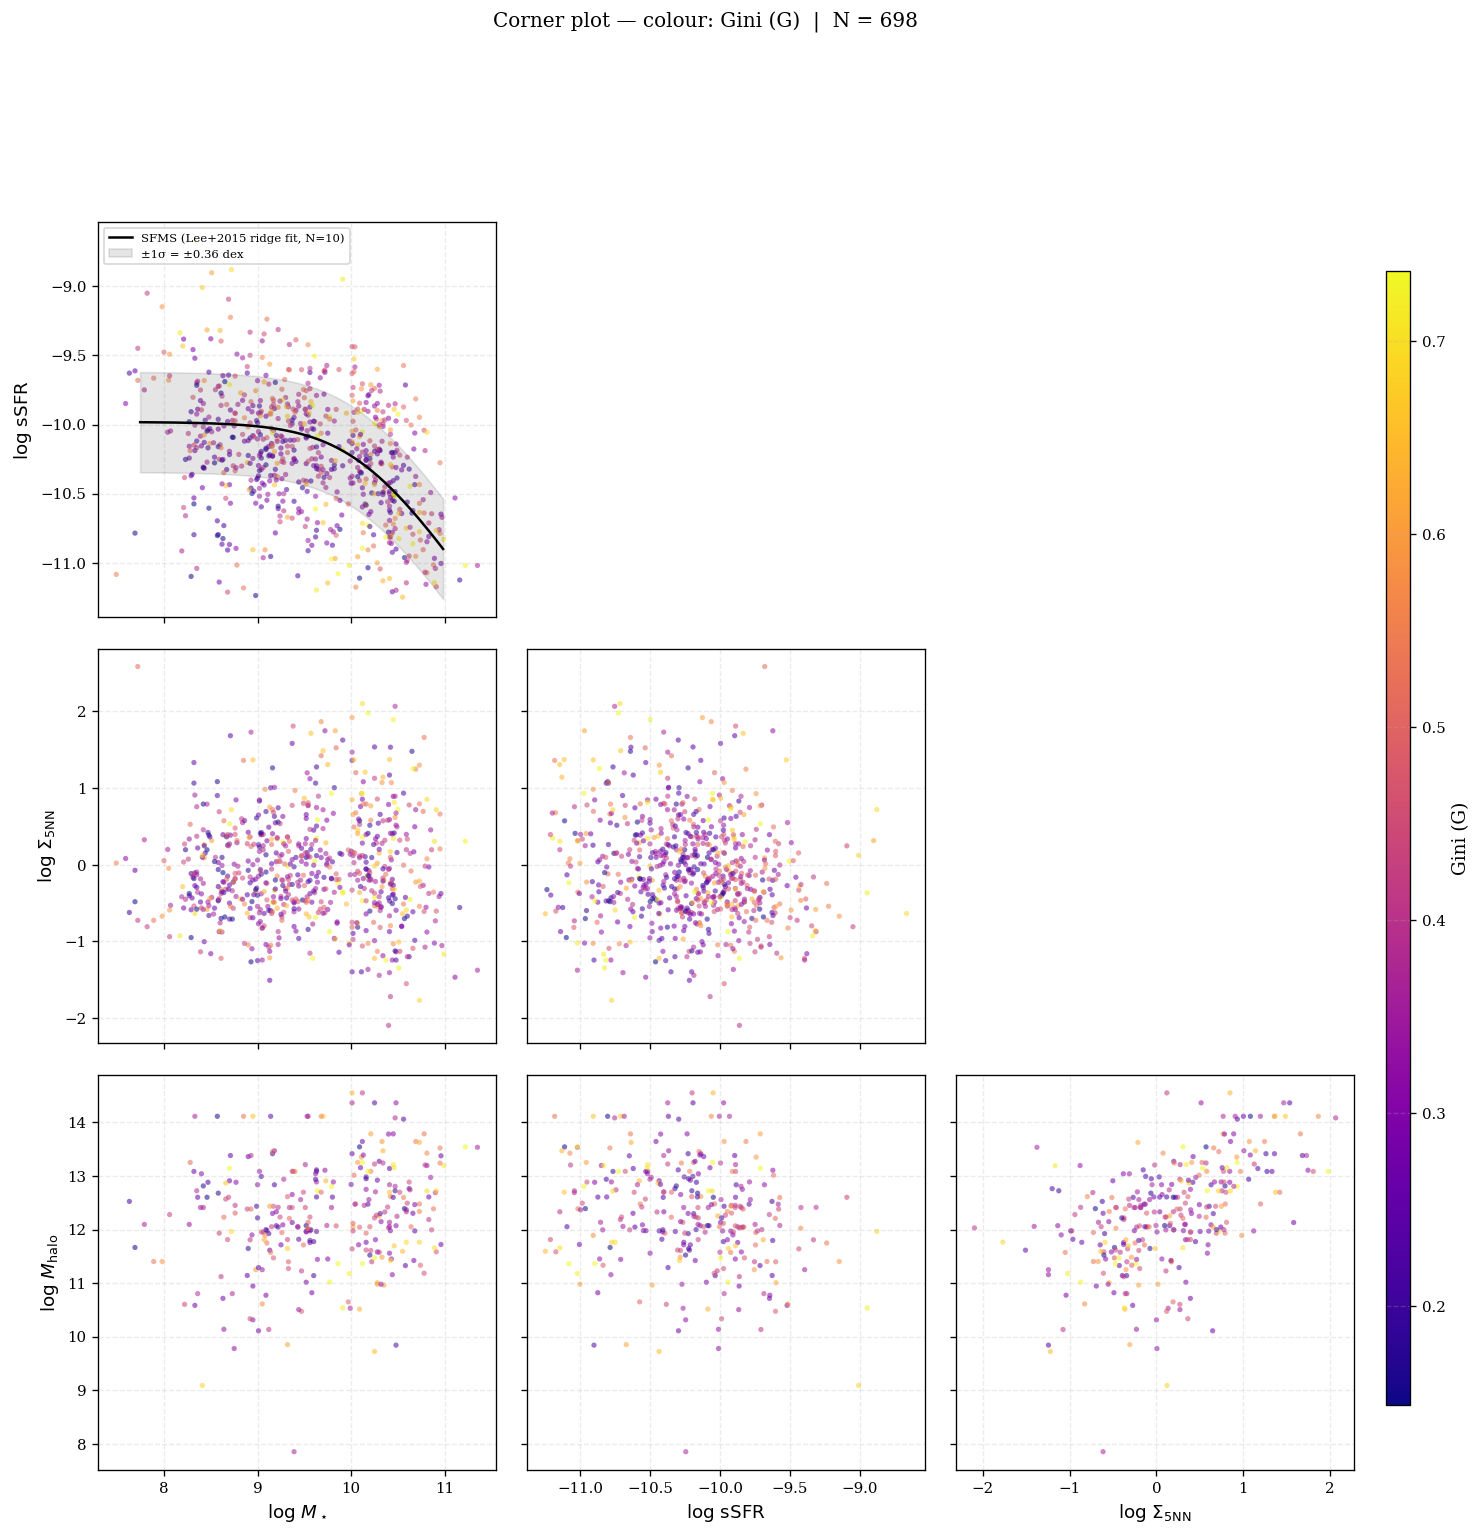

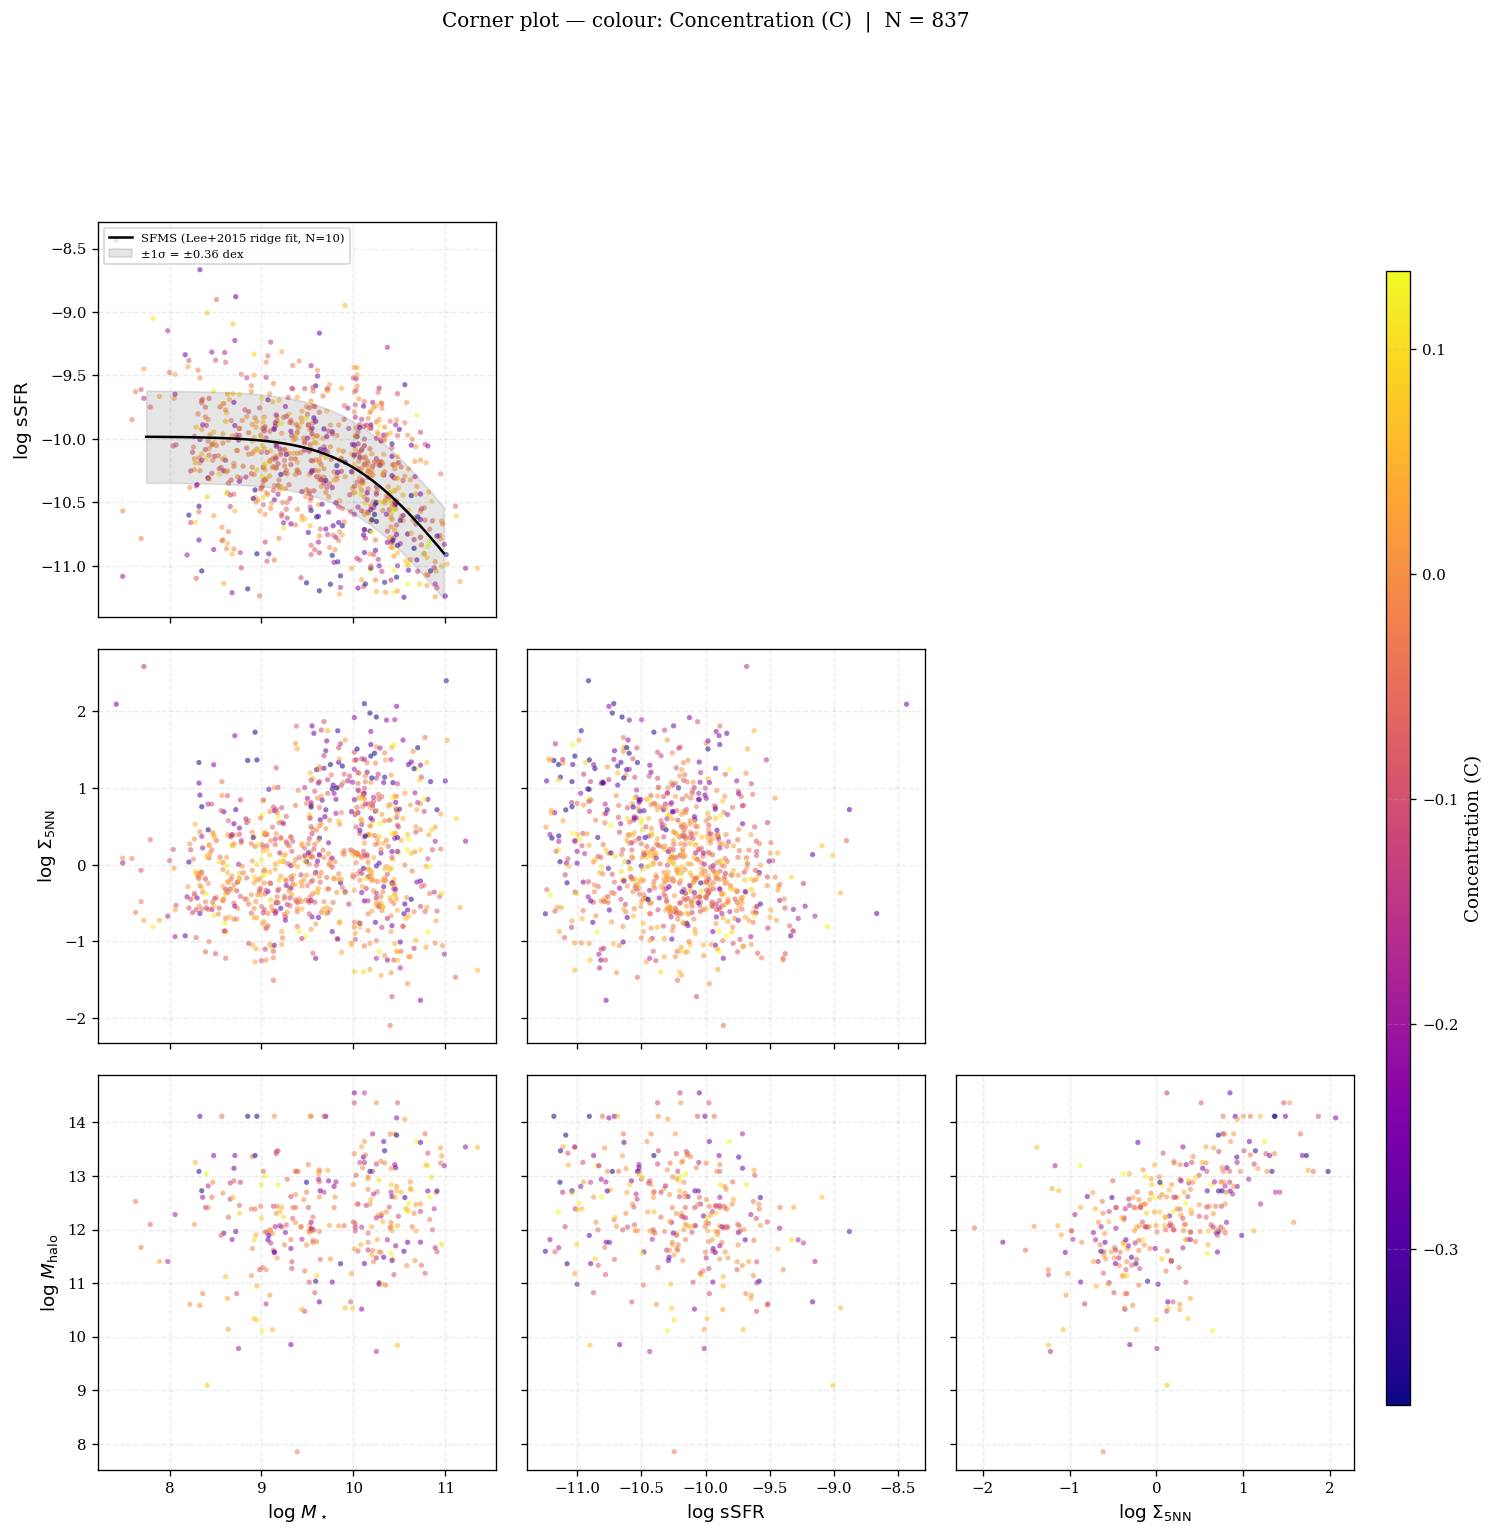

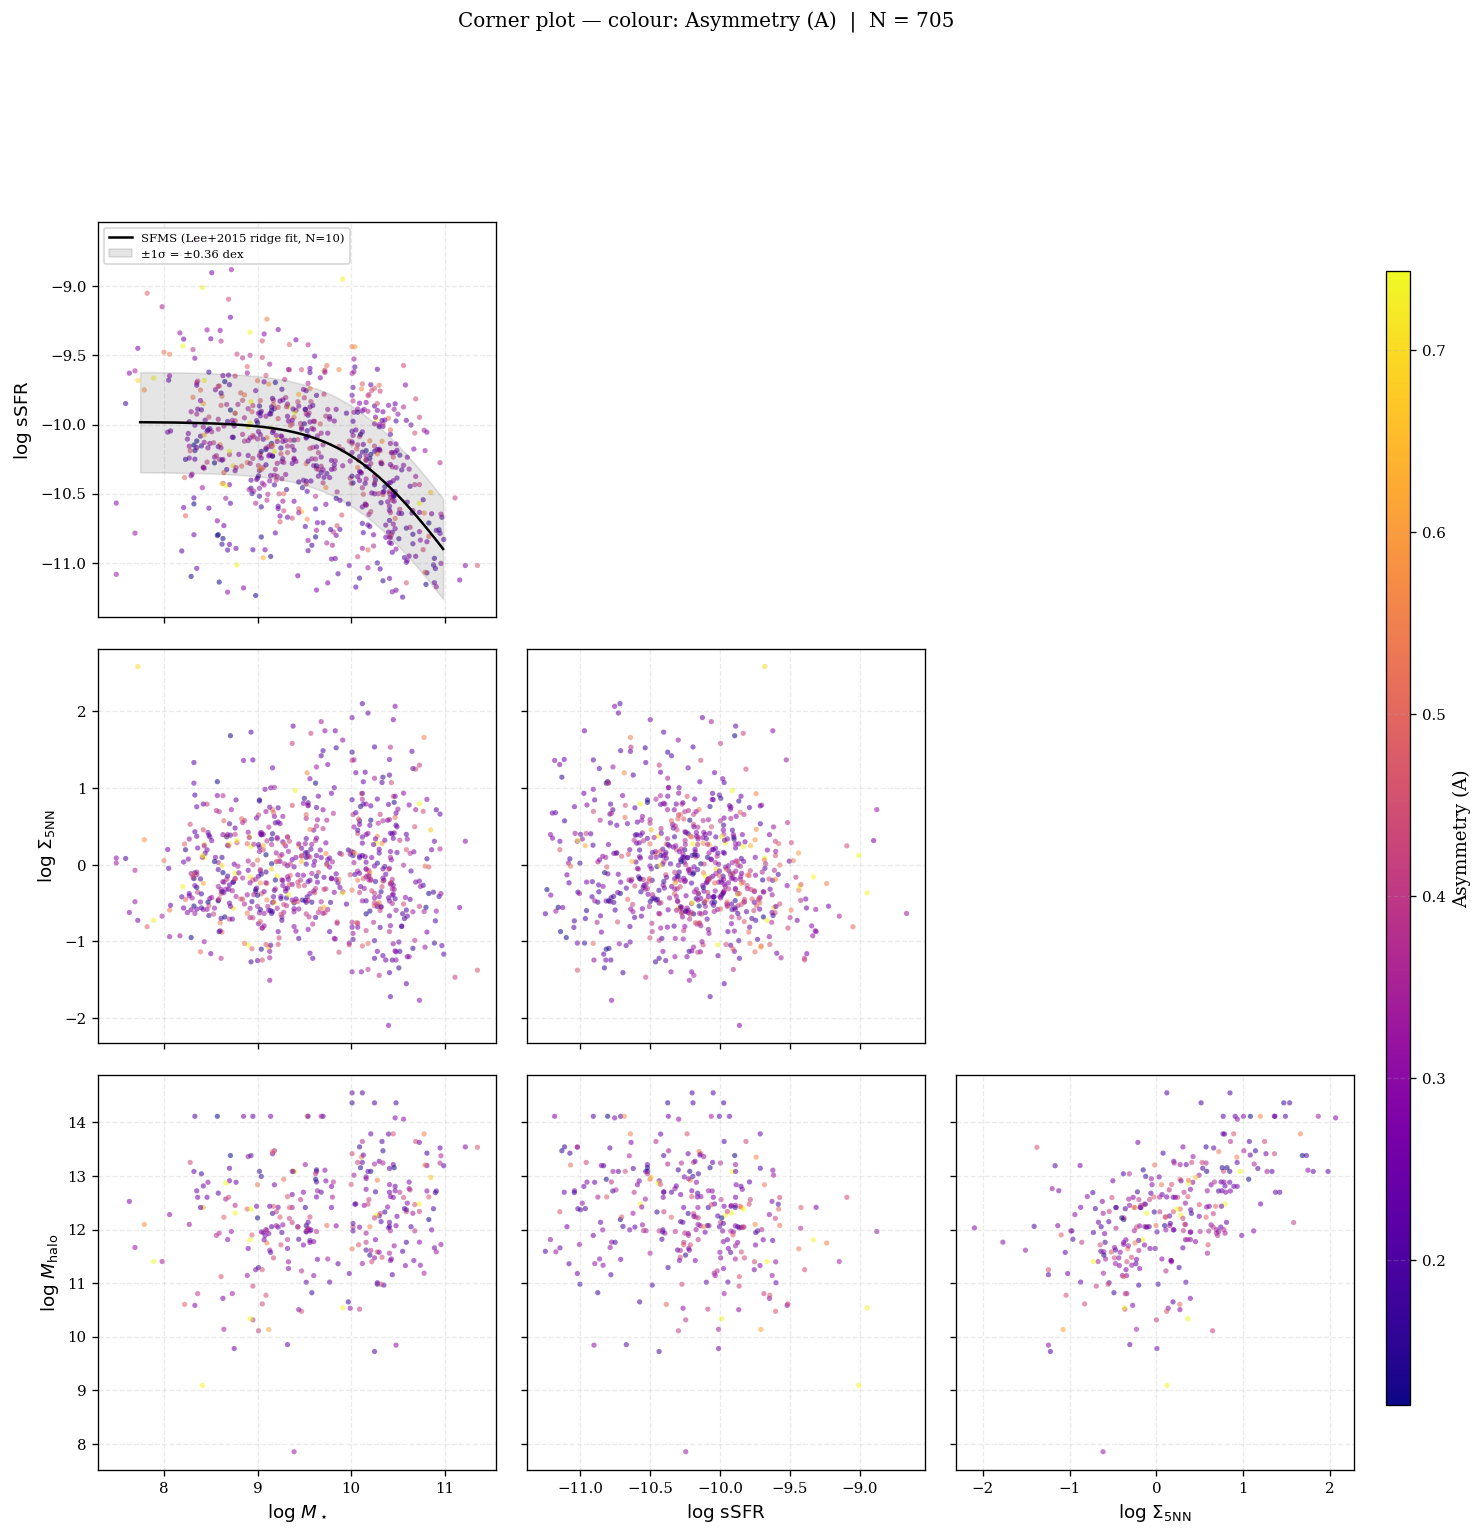

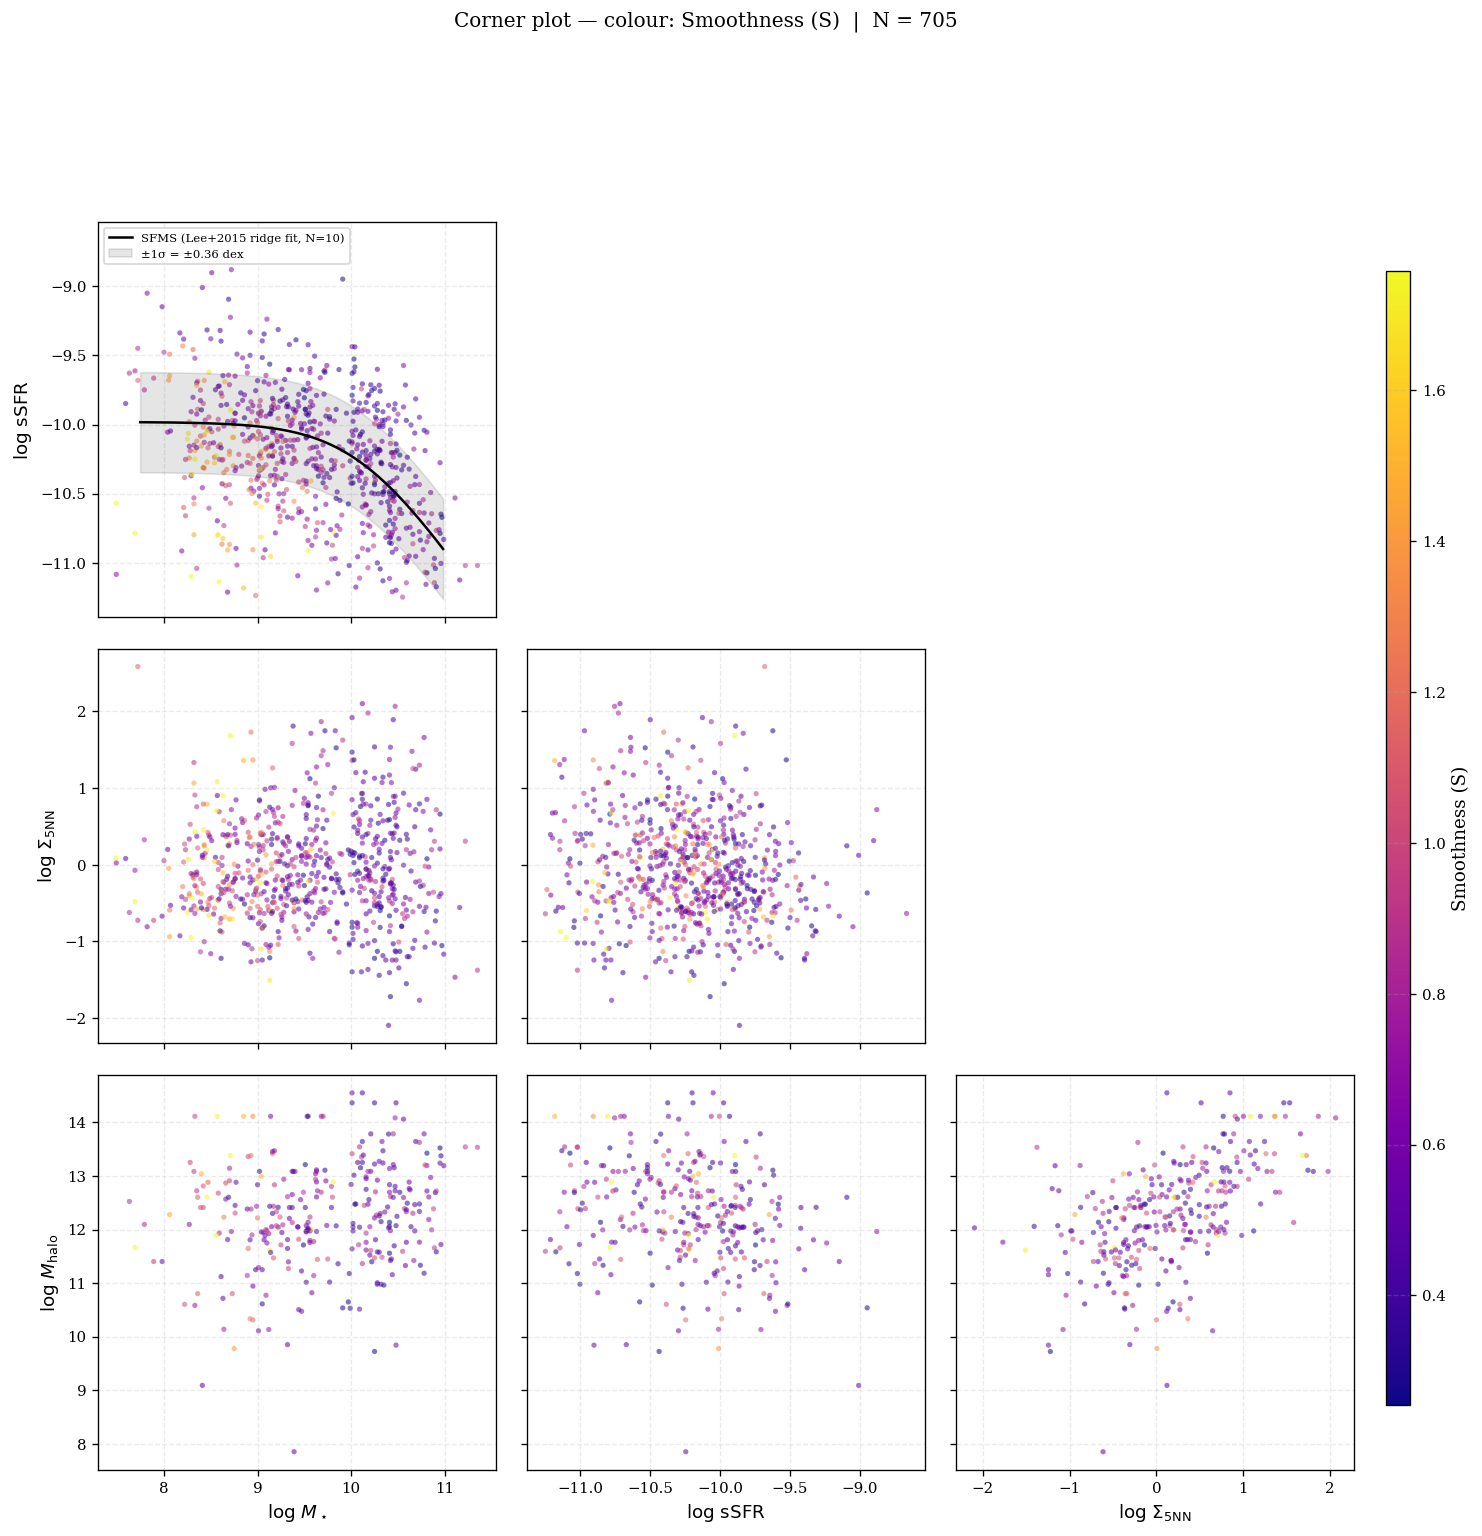

In [7]:
for m in ["G", "C", "A", "S"]:
    fig = plot_corner(df, sfms, metric=m, drivers=CORNER_DRIVERS, cmap=CORNER_CMAP,
                       sfms_show=SFMS_SHOW, sfms_scatter=SFMS_SCATTER)
    plt.show()